# Capstone-05: KNN Loan Approval Prediction
Student: Waqas Khan Niazi

Source: https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset

Default KNeighborsClassifier() compared with a training-only CV-tuned model. Y=1 (Approved); N=0 (Rejected). Loan_ID is excluded. Educational exercise, not an operational lending system.

Run this notebook from the backend directory, or from its parent project folder. In Colab, upload train.py and train.csv into the working directory before running; the cell below places train.csv in data/ if necessary.

In [1]:
from pathlib import Path
import sys, io, shutil, json
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, SVG, HTML
from sklearn.metrics import ConfusionMatrixDisplay
root=Path.cwd()
if (root/"backend/train.py").exists(): root=root/"backend"
if not (root/"train.py").exists():
    from google.colab import files
    files.upload()
(root/"data").mkdir(exist_ok=True)
if not (root/"data/train.csv").exists():
    if not (root/"train.csv").exists():
        from google.colab import files
        files.upload()
    shutil.copy(root/"train.csv",root/"data/train.csv")
sys.path.insert(0,str(root))
from train import train
raw=pd.read_csv(root/"data/train.csv")
display(HTML(raw.head().to_html()))
print("Shape:", raw.shape)
display(HTML(raw.isna().sum().to_frame("Missing values").to_html()))


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Shape: (614, 13)


,Missing values
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


## Preprocessing and evaluation design
Numerical columns are median-imputed; categorical columns are mode-imputed and one-hot encoded. All transformed features, including dummy columns, are standardized. Every step is fitted within the pipeline on training folds only. The target maps N to 0 and Y to 1. Stratified 80/20 split, random_state=42. The external test CSV has no labels and is not used to compute accuracy.

Default classifier: exactly KNeighborsClassifier(). Five-fold stratified cross-validation compares k=3,5,7, and tunes n_neighbors over 3,5,7,9,11,15,21. The held-out test is used only after selection.

In [2]:
default,tuned,report,experiments,comparison,data,search=train()
print(json.dumps(report,indent=2))
display(HTML(experiments.to_html(index=False)))
display(HTML(pd.DataFrame(search.cv_results_)[["param_knn__n_neighbors","mean_test_score","std_test_score"]].to_html(index=False)))


{
  "rows": 614,
  "train_rows": 491,
  "test_rows": 123,
  "selected_k": 15,
  "best_CV_accuracy": 0.7352298495155638,
  "default": {
    "accuracy": 0.7886178861788617,
    "confusion_matrix": [
      [
        16,
        22
      ],
      [
        4,
        81
      ]
    ]
  },
  "tuned": {
    "accuracy": 0.7317073170731707,
    "confusion_matrix": [
      [
        5,
        33
      ],
      [
        0,
        85
      ]
    ]
  },
  "majority_baseline_accuracy": 0.6910569105691057
}


k,CV_accuracy,CV_SD
3,0.708782,0.040413
5,0.704700,0.040165
7,0.716945,0.032761


param_knn__n_neighbors,mean_test_score,std_test_score
3,0.708782,0.040413
5,0.704700,0.040165
7,0.716945,0.032761
9,0.714842,0.034935
11,0.729107,0.034625
15,0.735230,0.025018
21,0.716904,0.017527


## Confusion matrices
Rows are actual classes; columns are predicted classes. Class order is Rejected (0), Approved (1).

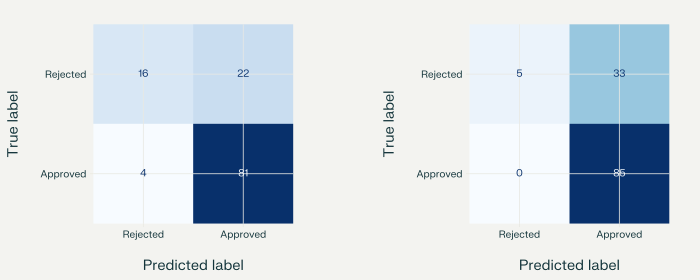

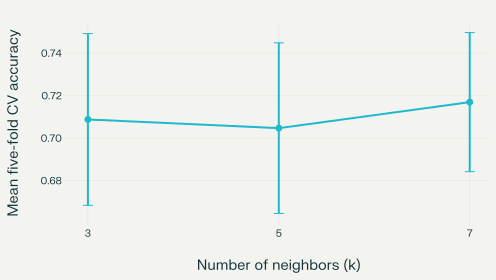

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,name,title in zip(axes,["default","tuned"],["Default KNN (k=5)",f"Tuned KNN (k={report['selected_k']})"]):
    ConfusionMatrixDisplay(confusion_matrix=np.array(report[name]["confusion_matrix"]),display_labels=["Rejected","Approved"]).plot(ax=ax,cmap="Blues",colorbar=False)
    ax.set_title(f"{title} | Accuracy {report[name]['accuracy']:.2%}")
fig.tight_layout()
buf=io.StringIO(); fig.savefig(buf,format="svg",bbox_inches="tight")
display(SVG(buf.getvalue())); plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4))
ax.errorbar(experiments.k,experiments.CV_accuracy,yerr=experiments.CV_SD,fmt="o-",capsize=5)
ax.set(xlabel="Number of neighbors (k)",ylabel="Mean five-fold CV accuracy",title="Training-only k experiment")
ax.set_xticks([3,5,7])
buf=io.StringIO(); fig.savefig(buf,format="svg",bbox_inches="tight")
display(SVG(buf.getvalue())); plt.close(fig)


## Interpretation
The CV-selected k may perform worse than the default model on a particular held-out test set; tuning is not a guarantee of improvement. Do not change the selected model based on test results. Inspect the confusion matrices: the tuned model misses most rejection-labeled applications despite its overall accuracy. This is an important limitation, not evidence that most applications should actually be approved.

No calibration, external validation, or protected-group fairness audit was conducted. Gender and marital status are included to match this educational dataset exercise, not to recommend their use in lending. Neighbor-label fractions are not calibrated probabilities. Currency and feature-unit metadata were not verified. Source license is unknown; confirm permission before public redistribution.